# Example application of RUBELLA to derive QC reports from RABIES outputs

This notebook provides a template for reading RABIES outputs using RUBELLA, and then generating customizable QC plots including measurements of network specificity using the RABIES Dice overlap approach, and group-level statistical summary reports. 
This is examplified separately for global connectivity, dual regression and seed-based connectivity analysis.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
from rubella import plotting
from matplotlib.backends.backend_pdf import PdfPages

%matplotlib inline

/home/vscode/miniconda/envs/rabies_compute/lib/python3.9/site-packages/nilearn/datasets/__init__.py:87: FutureWarning: Fetchers from the nilearn.datasets module will be updated in version 0.9 to return python strings instead of bytes and Pandas dataframes instead of Numpy arrays.
  warn("Fetchers from the nilearn.datasets module will be "


260805-20:34:11,108 nipype.utils WARNING:
	 A newer version (1.11.0) of nipy/nipype is available. You are using 1.10.0


In [ ]:
'''
These are inputs to RUBELLA's brain plotting function, which select a list of slices
to plot based on image indexing along the selected axis.
This likely needs to be adapted based on the resolution of the input data.
'''
num_slices = 10
selected_slices = list(np.array(range(num_slices))*2+13)
slices_per_row = num_slices


## load RABIES outputs into a DataObject

In [ ]:
rabies_out_name = 'rabies_Lake_multimodal_widefield_SLC_202607'
CR_name = f'FD_mot6_aCompCor_bandpass0.01-0.1_cut30edges_standard_smooth0.6'
rabies_out = f'/media/DATA3/gdesrosiersgregoire/preproc/Lake_multimodal_widefield_SLC/{rabies_out_name}'
rabies_out_name+= f'_{CR_name}'
os.makedirs(f'figures_QC/{rabies_out_name}', exist_ok=True)

template_file = f'{rabies_out}/bold_datasink/commonspace_resampled_template/commonspace_template.nii.gz'
brain_mask_file = f'{rabies_out}/bold_datasink/commonspace_mask/commonspace_template_brain_mask_resampled.nii.gz'
group_qc_csv = f'{rabies_out}/{CR_name}/data_diagnosis_datasink/analysis_QC/analysis_QC/sample_distributions/DR0_outlier_detection.csv'
group_qc_df = pd.read_csv(group_qc_csv)



In [5]:
from rubella.data_obj import DataObject
timeseries_file_list = glob.glob(f'{rabies_out}/{CR_name}/confound_correction_datasink/cleaned_timeseries/*/*_cleaned.nii.gz')
timeseries_file_list.sort()
censoring_file_list = glob.glob(f'{rabies_out}/{CR_name}/confound_correction_datasink/frame_censoring_mask/*/*_frame_censoring_mask.csv')

data_obj = DataObject(timeseries_file_list, brain_mask_file, img_id_list=None, fname_split='_cleaned', censoring_file_list=censoring_file_list, verbose=True)

/media/DATA3/gdesrosiersgregoire/preproc/Lake_multimodal_widefield_SLC/rabies_Lake_multimodal_widefield_SLC_202607/FD_mot6_aCompCor_bandpass0.01-0.1_cut30edges_standard_smooth0.6/confound_correction_datasink/cleaned_timeseries/_split_name_sub-SLC01_ses-1_task-led_run-2_bold/sub-SLC01_ses-1_task-led_run-2_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/Lake_multimodal_widefield_SLC/rabies_Lake_multimodal_widefield_SLC_202607/FD_mot6_aCompCor_bandpass0.01-0.1_cut30edges_standard_smooth0.6/confound_correction_datasink/cleaned_timeseries/_split_name_sub-SLC01_ses-1_task-led_run-4_bold/sub-SLC01_ses-1_task-led_run-4_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/Lake_multimodal_widefield_SLC/rabies_Lake_multimodal_widefield_SLC_202607/FD_mot6_aCompCor_bandpass0.01-0.1_cut30edges_standard_smooth0.6/confound_correction_datasink/cleaned_timeseries/_split_name_sub-SLC01_ses-1_task-led_run-6_bold/sub-SLC01_ses-1_task-led_run-6_bold_cleaned.nii.gz
/media/DATA3/gdesrosie

## select ICA components

Generating a figure with dimensions (9.440000140666962, 7.200000107288361), 10 rows and 1 columns.


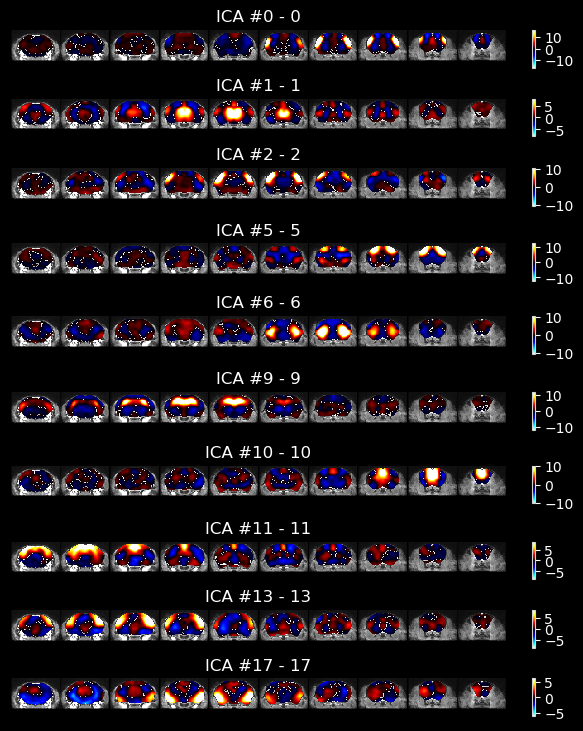

In [ ]:
IC_file = '/media/DATA3/gdesrosiersgregoire/preproc/Lake_multimodal_widefield_SLC/rabies_Lake_multimodal_widefield_SLC_202607/FD_mot6_aCompCor_bandpass0.01-0.1_cut30edges_standard_smooth0.6/group_ica30/group_melodic.ica/melodic_IC.nii.gz'
IC_idx = [0,1,2,5,6,9,10,11,13,17]
IC_name='30IC_Lake_SLC'
IC_idx_names = IC_idx


IC_arr = data_obj._load_img_to_array(IC_file)
data_list = [IC_arr[i,:] for i in IC_idx]
if len(data_list)==1:
    data_list = data_list*2

plot_size_scale = 0.08
vmax = None
fig,ax_list,cbar_list = plotting.plot_many_brains(
        data_list,brain_mask_file,template_file,
        fig=None,ax_list=None,plot_size_scale=plot_size_scale,num_brain_per_row=1,
        plane='coronal', selected_slices=selected_slices, slices_per_row=slices_per_row, # slice selection
        cmap='cold_hot', vmax=vmax, vmin=None, plot_cbar=True, # cmap range
        fixed_threshold=0.05,percent_thresholding=False,top_percent=10, # image thresholding
        )

i=0
for ax in ax_list:
    ax.set_title(f'ICA #{IC_idx[i]} - {IC_idx_names[i]}', color='white')
    i+=1

## select seeds

In [7]:
from rubella.basic_fc import seed_based_FC

seed_names = ['SS_frontal','SS_dorsal','MO','ACA','RSP','ECT_AI','ORB_limbic','VIS',
              'THAL','basal_ganglia','HIP','AMYG','HY']
seed_file_list = []
for name in seed_names:
    seed_file_list.extend(glob.glob(f'/home/gdesrosiersgregoire/atlases/DSURQE_seeds/N162_RAS_resampled/*{name}*_resampled.nii.gz'))
seed_set_name = 'RABIES_seeds'

if not len(seed_file_list)==len(seed_names):
    raise

# Quality Control

In [8]:
import rubella.qc.utils as qc_utils
from rubella.qc.report import group_stats_QC_plot
from rabies.analysis_pkg.diagnosis_pkg.analysis_QC import plot_QC_distributions

In [9]:
qc_metric_dict = {'DR confound corr.':[], 'FD-DVARS corr.':[], '$CR_{SD}$':[], 'Mean FD (mm)':[], 'Degrees of freedom':[]}
for img_id in data_obj.img_id_list:
    for df_id in list(group_qc_df['scan ID']):
        if img_id==df_id:
            sub_df = group_qc_df[group_qc_df['scan ID']==df_id]
            qc_metric_dict['DR confound corr.'].append(sub_df['DR confound corr.'].values[0])
            qc_metric_dict['FD-DVARS corr.'].append(sub_df['FD-DVARS corr.'].values[0])
            qc_metric_dict['$CR_{SD}$'].append(sub_df['$CR_{SD}$'].values[0])
            #qc_metric_dict['CR $R^{2}$'].append(sub_df['CR_VE'].values[0])
            qc_metric_dict['Mean FD (mm)'].append(sub_df['mean FD'].values[0])
            if 'tDOF' in sub_df:
                qc_metric_dict['Degrees of freedom'].append(sub_df['tDOF'].values[0])

if len(qc_metric_dict['Degrees of freedom'])==0:
    qc_metric_dict.pop('Degrees of freedom')

for key in qc_metric_dict:
    qc_metric_dict[key] = np.array(qc_metric_dict[key])

fd_qc_dict = {}
fd_qc_dict['Mean FD (mm)'] = qc_metric_dict['Mean FD (mm)']

#also set the bounds for the scatter plots
x_bounds_dict = {'Network specificity (Dice)':[0,1.0]}
y_bounds_dict = {'DR confound corr.':[0,1.0], 'FD-DVARS corr.':[-0.1,1.0], 'CR $R^{2}$':[0.0,1.0]}


## Global connectivity

In [ ]:
'''
Compute dual regression using the selected ICA components
'''
from rubella.basic_fc import compute_global_connectivity
GC_dict = compute_global_connectivity(data_obj.timeseries_dict, data_obj.img_id_list, verbose=False)

/home/vscode/miniconda/envs/rabies_compute/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/vscode/miniconda/envs/rabies_compute/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/tmp/ipykernel_11981/2489269622.py:14: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "bbox" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig(fig_path, bbox='tight')


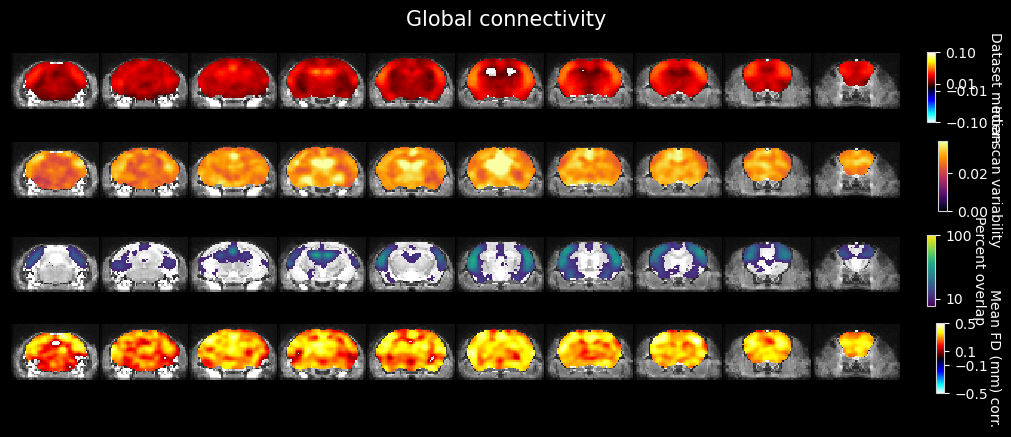

In [ ]:
'''
Generate group-level statistical maps for global connectivity
'''
fig,axes = group_stats_QC_plot(
        GC_dict, 
        brain_mask_file, 
        template_file,
        selected_slices, 
        slices_per_row=slices_per_row, 
        threshold=True, 
        vmax_FC=0.1, 
        include_stat=['avg', 'sd', 'overlap'],
        qc_data_dict=fd_qc_dict,
        )
fig.suptitle('Global connectivity', fontsize=15, color='white')
fig_path = f'figures_QC/{rabies_out_name}/GC_group_stats_{rabies_out_name}.png'
fig.savefig(fig_path, bbox='tight')


In [ ]:
'''
Generate RABIES-like dataset QC scatter plots for each selected ICA component
'''

FC_amp_list = [np.sqrt(GC_dict[img_id] ** 2).sum() for img_id in data_obj.img_id_list]
dice_list = qc_utils.get_dice_list(GC_dict, avg_type='median', top_percent=10)

net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}
fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)

fig_path = f'figures_QC/{rabies_out_name}/GC_scatter_{rabies_out_name}.png'
fig.savefig(fig_path, bbox='tight')
plt.close()


/tmp/ipykernel_11981/928922523.py:8: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "bbox" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig(fig_path, bbox='tight')


## dual regression

In [ ]:
'''
Compute dual regression using the selected ICA components
'''
from rubella.basic_fc import compute_dual_regression
DR_dict = compute_dual_regression(timeseries_dict=data_obj.timeseries_dict, brain_mask_file=data_obj.brain_mask_file, img_id_list=data_obj.img_id_list, IC_maps=IC_arr, IC_idx=IC_idx)

In [ ]:
'''
Generate group-level statistical maps for each selected ICA component
'''
num_ICs = len(IC_idx)
fig_set = {}
for i in range(num_ICs):
    FC_map_dict = {}
    for img_id in data_obj.img_id_list:
        FC_map_dict[img_id] = DR_dict[img_id]['DR_maps'][:,i]

    fig,axes = group_stats_QC_plot(FC_map_dict, brain_mask_file, template_file, selected_slices, slices_per_row=slices_per_row, threshold=True, include_stat=['avg', 'sd', 'overlap'], qc_data_dict=fd_qc_dict)
    fig.suptitle(f'DR ICA #{IC_idx[i]}', fontsize=15, color='white')
    fig_set[i] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f"figures_QC/{rabies_out_name}/DR_group_stats_{IC_name}_{rabies_out_name}.pdf"
with PdfPages(pdf_path) as pdf:
    for i in range(num_ICs):
        fig = fig_set[i]
        pdf.savefig(fig)


In [ ]:
'''
Generate RABIES-like dataset QC scatter plots for each selected ICA component
'''

num_ICs = len(IC_idx)
fig_set = {}
for i in range(num_ICs):
    FC_map_dict = {}
    for img_id in data_obj.img_id_list:
        FC_map_dict[img_id] = DR_dict[img_id]['DR_maps'][:,i]

    dice_list = qc_utils.get_dice_list(FC_map_dict, avg_FC=None, avg_type='median', top_percent=10)
    FC_amp_list = [np.sqrt(FC_map_dict[img_id] ** 2).sum() for img_id in FC_map_dict]
    net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}

    fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)
    fig.suptitle(f'ICA #{IC_idx[i]}', fontsize=30, color='white')
    fig_set[i] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f"figures_QC/{rabies_out_name}/DR_scatter_{IC_name}_{rabies_out_name}.pdf"
with PdfPages(pdf_path) as pdf:
    for i in range(num_ICs):
        fig = fig_set[i]
        pdf.savefig(fig)


## Seed based analysis

In [ ]:
'''
Compute seed-based connectivity for each seed in the seed list
'''
SBC_dict = {}
seed_arr_dict = {}

for seed_name, seed_file in zip(seed_names, seed_file_list):
    seed_arr_dict[seed_name] = data_obj._load_img_to_array(seed_file, input_is_mask=True)
    SBC_dict[seed_name] = seed_based_FC(timeseries_dict=data_obj.timeseries_dict, brain_mask_file=data_obj.brain_mask_file, img_id_list=data_obj.img_id_list, seed_roi=seed_arr_dict[seed_name], z_corr=False)



                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                


/media/DATA3/gdesrosiersgregoire/software/RUBELLA/rubella/basic.py:75: RuntimeWarning: invalid value encountered in divide
  r = r_num/r_den



                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                

                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                

                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                

                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                

                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                

                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
                

                The image is resampled with the assumption that it occupies 
                the same space as the brain mask.
  

/tmp/ipykernel_13224/3178536982.py:20: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "bbox" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig(fig_path, bbox='tight')


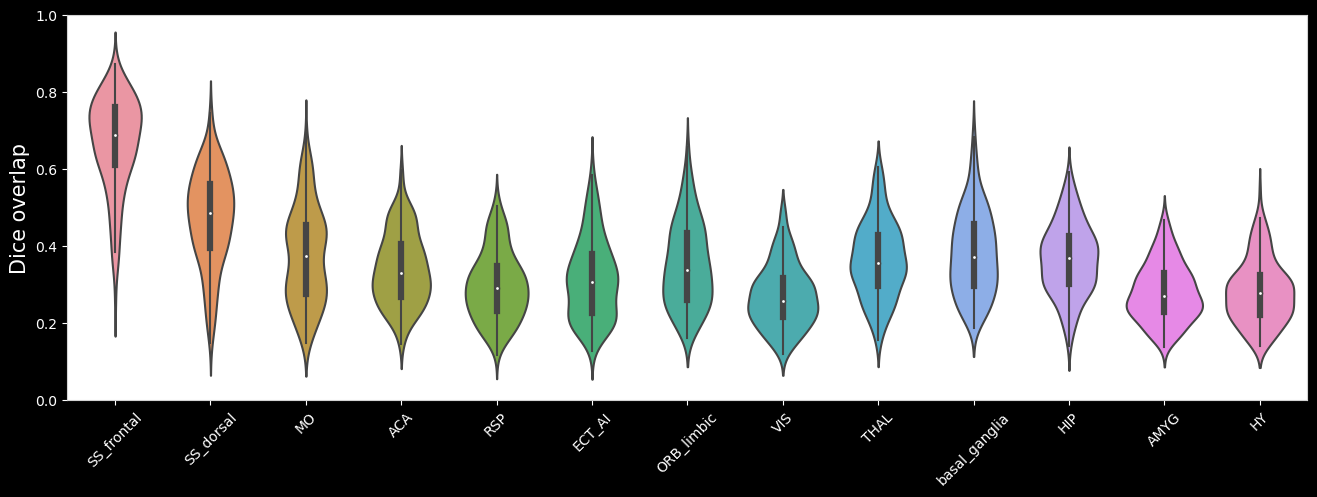

In [ ]:
'''
Plot the distribution of network specificity (Dice) for each seed
'''

dice_l = []
title_l = []

for seed_name in seed_names:
    dice_list = qc_utils.get_dice_list(SBC_dict[seed_name], avg_FC=None, avg_type='median', top_percent=10, seed_mask_arr=seed_arr_dict[seed_name])

    dice_l += dice_list
    title_l += [seed_name]*len(dice_list)
        
import seaborn as sns
fig,ax = plt.subplots(1,1,figsize=(16,5))
sns.violinplot(ax=ax, y=dice_l, x=title_l)

ax.tick_params(axis='x', rotation=45)
ax.set_ylim([0,1])
ax.set_ylabel('Dice overlap', fontsize=15, color='white')

fig_path = f'figures_QC/{rabies_out_name}/SBC_dice_{seed_set_name}_{rabies_out_name}_N53unilateral.png'
fig.savefig(fig_path, bbox='tight')

In [ ]:
'''
Generate group-level statistical maps for each seed.
'''
fig_set = {}
for seed_name in seed_names:
    fig,axes = group_stats_QC_plot(SBC_dict[seed_name], brain_mask_file, template_file, selected_slices, slices_per_row=slices_per_row, include_stat=['avg', 'sd', 'overlap'], qc_data_dict = fd_qc_dict)
    fig.suptitle('Seed: '+seed_name, fontsize=15, color='white')
    fig_set[seed_name] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f"figures_QC/{rabies_out_name}/SBC_group_stats_{seed_set_name}_{rabies_out_name}.pdf"
with PdfPages(pdf_path) as pdf:
    for seed_name in seed_names:
        fig = fig_set[seed_name]
        pdf.savefig(fig)


In [ ]:
'''
Generate RABIES-like dataset QC scatter plots for each seed
'''
fig_set = {}
for seed_name in seed_names:

    dice_list = qc_utils.get_dice_list(SBC_dict[seed_name], avg_FC=None, avg_type='median', top_percent=10, seed_mask_arr=seed_arr_dict[seed_name])
    FC_amp_list = [np.sqrt(SBC_dict[seed_name][img_id] ** 2).sum() for img_id in SBC_dict[seed_name]]
    net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}

    fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)
    fig.suptitle(seed_name, fontsize=30, color='white')
    fig_set[seed_name] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f'figures_QC/{rabies_out_name}/SBC_scatter_{seed_set_name}_{rabies_out_name}.pdf'
with PdfPages(pdf_path) as pdf:
    for seed_name in seed_names:
        fig = fig_set[seed_name]
        pdf.savefig(fig)
        